<a href="https://colab.research.google.com/github/sathiyapriyaprakash/Digitalportfolio/blob/main/Travel%20insurance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Travel  Insurance Prediction**

# **Import Libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


# **Dataset Upload**

In [8]:
uploaded = files.upload()

file_name = next(
    name for name in uploaded
    if name.lower().endswith(".csv")
)

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Saving TravelInsurancePrediction.csv to TravelInsurancePrediction (2).csv
Dataset loaded successfully!
Dataset shape: (1987, 10)


,Unnamed: 0,Age,Employment Type,GraduateOrNot,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
0,0,31,Government Sector,Yes,400000,6,1,No,No,0
1,1,31,Private Sector/Self Employed,Yes,1250000,7,0,No,No,0
2,2,34,Private Sector/Self Employed,Yes,500000,4,1,No,No,1
3,3,28,Private Sector/Self Employed,Yes,700000,3,1,No,No,0
4,4,28,Private Sector/Self Employed,Yes,700000,8,1,Yes,No,0


# **Data Cleaning**

In [14]:
# Remove unwanted spaces from column names
df.columns = df.columns.str.strip()

# Remove row-index column
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset shape: (1987, 9)

Column names:
['Age', 'Employment Type', 'GraduateOrNot', 'AnnualIncome', 'FamilyMembers', 'ChronicDiseases', 'FrequentFlyer', 'EverTravelledAbroad', 'TravelInsurance']

Missing values:
Age                    0
Employment Type        0
GraduateOrNot          0
AnnualIncome           0
FamilyMembers          0
ChronicDiseases        0
FrequentFlyer          0
EverTravelledAbroad    0
TravelInsurance        0
dtype: int64

Duplicate rows: 738

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1987.0,NaN,NaN,NaN,29.650226,2.913308,25.0,28.0,29.0,32.0,35.0
Employment Type,1987,2,Private Sector/Self Employed,1417,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GraduateOrNot,1987,2,Yes,1692,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AnnualIncome,1987.0,NaN,NaN,NaN,932762.959235,376855.684748,300000.0,600000.0,900000.0,1250000.0,1800000.0
FamilyMembers,1987.0,NaN,NaN,NaN,4.752894,1.60965,2.0,4.0,5.0,6.0,9.0
ChronicDiseases,1987.0,NaN,NaN,NaN,0.277806,0.44803,0.0,0.0,0.0,1.0,1.0
FrequentFlyer,1987,2,No,1570,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EverTravelledAbroad,1987,2,No,1607,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TravelInsurance,1987.0,NaN,NaN,NaN,0.357323,0.479332,0.0,0.0,0.0,1.0,1.0


# **Target Column and Features**

In [15]:
target_col = "TravelInsurance"

if target_col not in df.columns:
    raise ValueError(
        "TravelInsurance target column கிடைக்கவில்லை!"
    )

df = df.dropna(subset=[target_col]).copy()

# Target must contain only 0 and 1
y = pd.to_numeric(
    df[target_col], errors="raise"
).astype(int)

if not set(y.unique()).issubset({0, 1}):
    raise ValueError(
        "TravelInsurance column-ல் 0 மற்றும் 1 values இருக்க வேண்டும்."
    )

X = df.drop(columns=[target_col]).copy()

print("Target column:", target_col)
print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget and features ready!")

Target column: TravelInsurance

Target distribution:
TravelInsurance
0    1277
1     710
Name: count, dtype: int64

Features:
['Age', 'Employment Type', 'GraduateOrNot', 'AnnualIncome', 'FamilyMembers', 'ChronicDiseases', 'FrequentFlyer', 'EverTravelledAbroad']

Target and features ready!


# **EDA(Exploratory Data Analysis)**

*a.Target distribution-Bar chart*

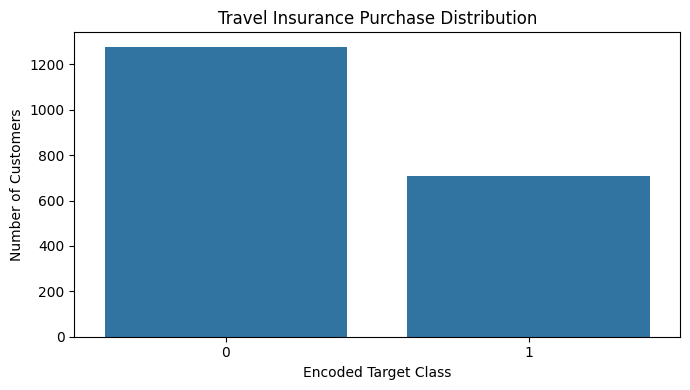

Class proportions:
TravelInsurance
0    0.642677
1    0.357323
Name: proportion, dtype: float64


In [19]:
target_counts = pd.Series(y).value_counts().sort_index()

plt.figure(figsize=(7, 4))

sns.barplot(
    x=target_counts.index.astype(str),
    y=target_counts.values
)

plt.title("Travel Insurance Purchase Distribution")
plt.xlabel("Encoded Target Class")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print("Class proportions:")
print(pd.Series(y).value_counts(normalize=True).sort_index())

*b.Numeric columns-histogram*

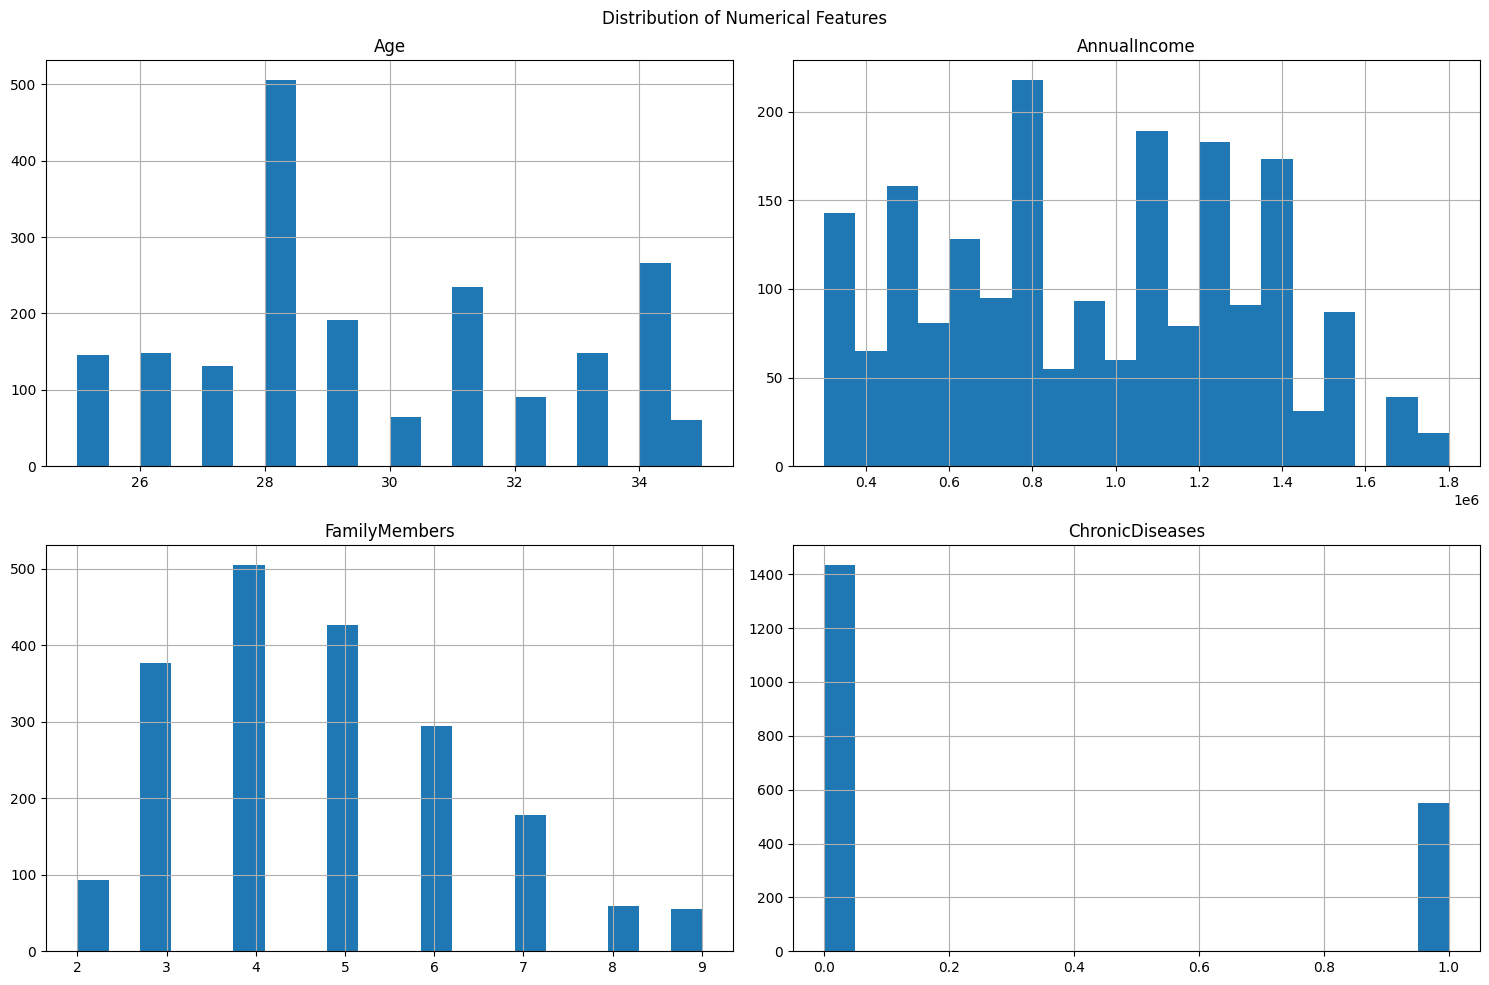

In [26]:
numeric_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

X[numeric_cols].hist(
    figsize=(15, 10),
    bins=20
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

*c.Correlation heatmap*

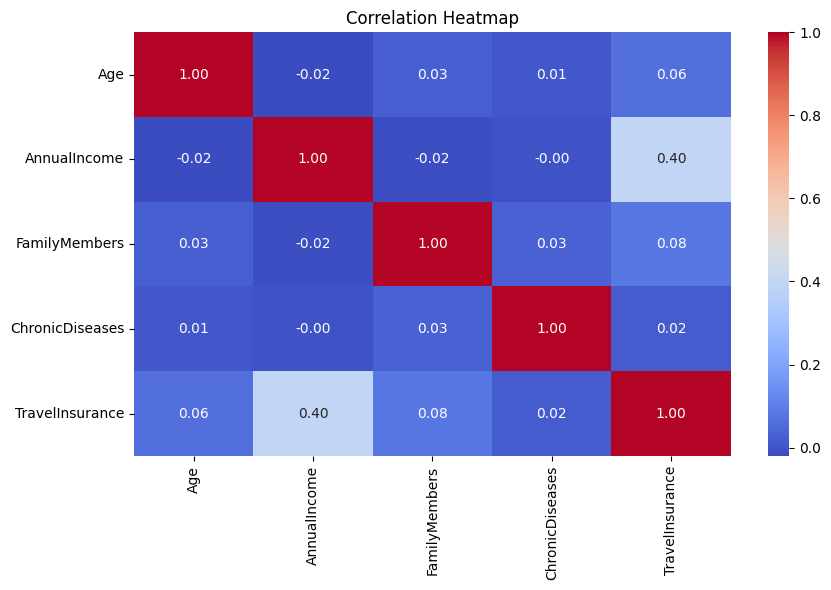

In [27]:
corr_data = X.select_dtypes(
    include=np.number
).copy()

corr_data["TravelInsurance"] = y

plt.figure(figsize=(9, 6))

sns.heatmap(
    corr_data.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

*d.Categorical features analysis*

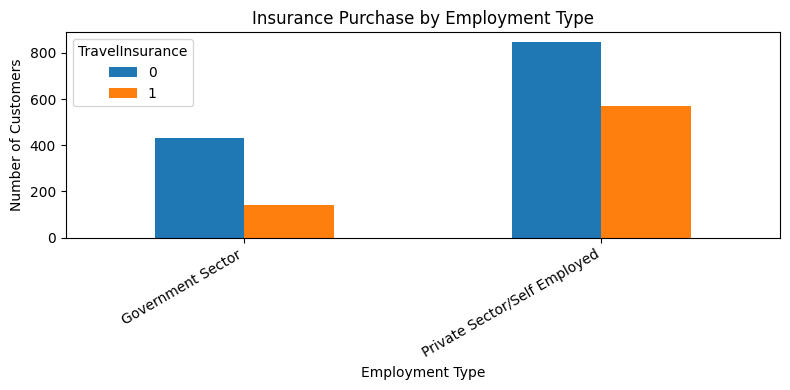

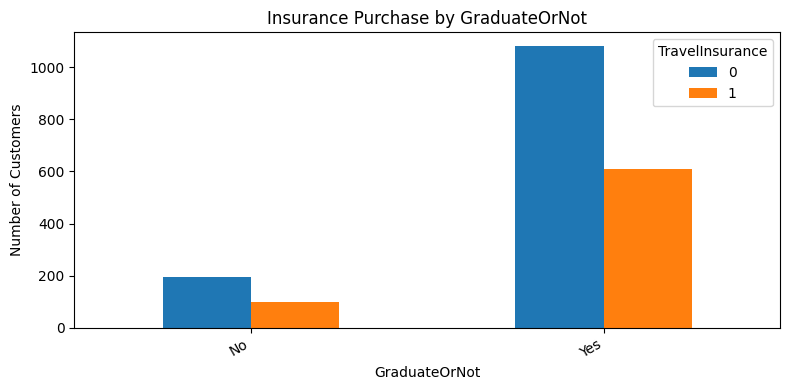

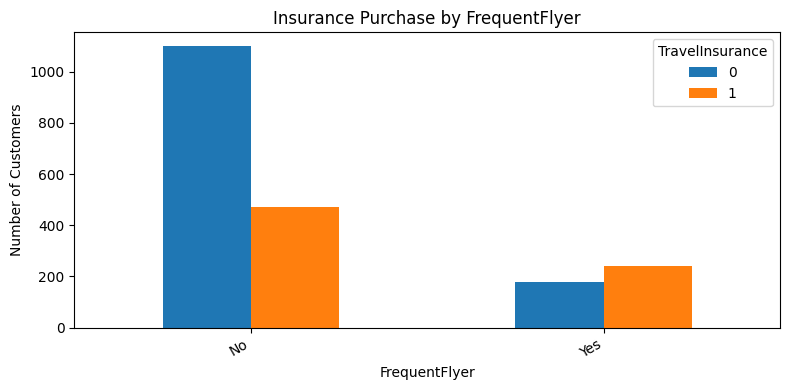

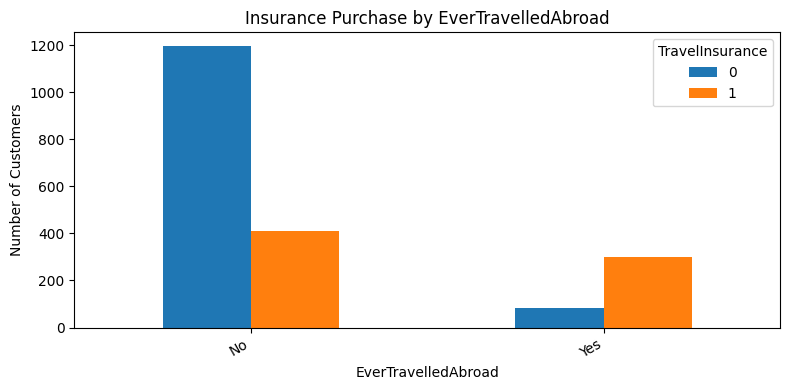

In [28]:
cat_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

for col in cat_cols:
    plot_df = pd.DataFrame({
        "Feature": X[col].fillna("Missing").astype(str),
        "TravelInsurance": y
    })

    chart_data = plot_df.groupby(
        ["Feature", "TravelInsurance"]
    ).size().unstack(fill_value=0)

    chart_data.plot(kind="bar", figsize=(8, 4))

    plt.title(f"Insurance Purchase by {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

# **Feature Engineering**

In [29]:
X_fe = X.copy()

# Income per family member
X_fe["AnnualIncome"] = pd.to_numeric(
    X_fe["AnnualIncome"],
    errors="coerce"
)

X_fe["FamilyMembers"] = pd.to_numeric(
    X_fe["FamilyMembers"],
    errors="coerce"
)

family_size = X_fe["FamilyMembers"].replace(0, np.nan)

X_fe["IncomePerFamilyMember"] = (
    X_fe["AnnualIncome"] / family_size
)

# Age group
X_fe["Age"] = pd.to_numeric(
    X_fe["Age"],
    errors="coerce"
)

X_fe["AgeGroup"] = pd.cut(
    X_fe["Age"],
    bins=[0, 25, 35, 45, 55, np.inf],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "Above 55"
    ],
    include_lowest=True
).astype("object")

print("Feature engineering completed!")
print("Original features:", X.shape[1])
print("New features:", X_fe.shape[1])

display(X_fe.head())

Feature engineering completed!
Original features: 8
New features: 10


,Age,Employment Type,GraduateOrNot,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,IncomePerFamilyMember,AgeGroup
0,31,Government Sector,Yes,400000,6,1,No,No,66666.666667,26-35
1,31,Private Sector/Self Employed,Yes,1250000,7,0,No,No,178571.428571,26-35
2,34,Private Sector/Self Employed,Yes,500000,4,1,No,No,125000.000000,26-35
3,28,Private Sector/Self Employed,Yes,700000,3,1,No,No,233333.333333,26-35
4,28,Private Sector/Self Employed,Yes,700000,8,1,Yes,No,87500.000000,26-35


## **Train/Test Split and Preprocessing**

In [32]:
X_model = X_fe.replace(
    [np.inf, -np.inf],
    np.nan
).copy()

# Remove completely empty columns
empty_cols = X_model.columns[
    X_model.isna().all()
].tolist()

X_model = X_model.drop(columns=empty_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

num_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

cat_cols = [
    col for col in X_train.columns
    if col not in num_cols
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols)
    ]
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Preprocessing ready!")

Training rows: 1589
Testing rows: 398
Preprocessing ready!


# **Create Machine Learning Models**

In [37]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    )
}

print("Models created successfully!")
print(list(models.keys()))

Models created successfully!
['Logistic Regression', 'Random Forest', 'Decision Tree']


## **Train Models and Calculate Metrics**

In [42]:
trained_models = {}
results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", clone(model))
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, y_prob)
    })

    trained_models[name] = pipeline

    print(name, "trained successfully!")

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1_Score",
    ascending=False
).reset_index(drop=True)

print("\nMODEL COMPARISON RESULTS")

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1_Score": "{:.4f}",
        "ROC_AUC": "{:.4f}"
    })
)

Logistic Regression trained successfully!
Random Forest trained successfully!
Decision Tree trained successfully!

MODEL COMPARISON RESULTS


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Random Forest,0.7613,0.6942,0.5915,0.6388,0.7568
1,Logistic Regression,0.7261,0.6093,0.6479,0.6280,0.7608
2,Decision Tree,0.7161,0.5986,0.6197,0.6090,0.7171


## **Model Comparison Bar Chart**

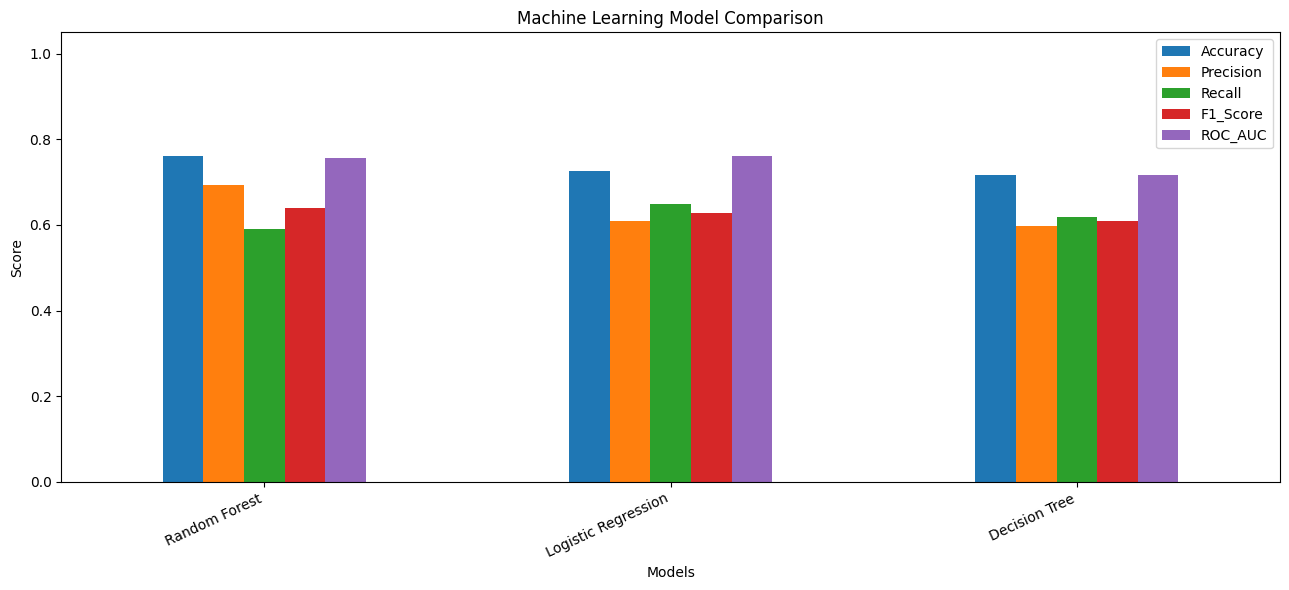

In [43]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score",
    "ROC_AUC"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## **Classification Report & Confusion Matrix**

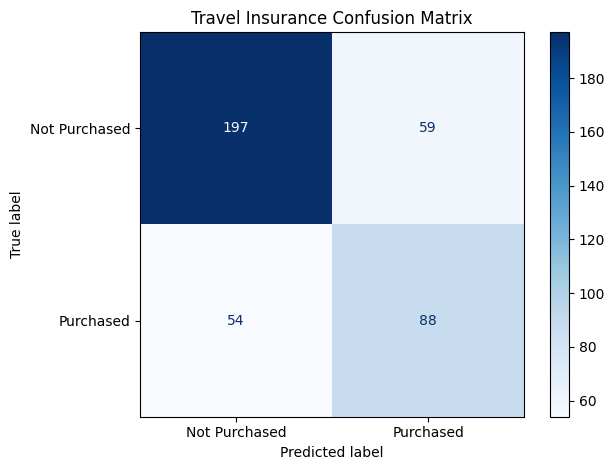

In [46]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Purchased", "Purchased"]
)

disp.plot(cmap="Blues")
plt.title("Travel Insurance Confusion Matrix")
plt.tight_layout()
plt.show()

## **ROC Curve**

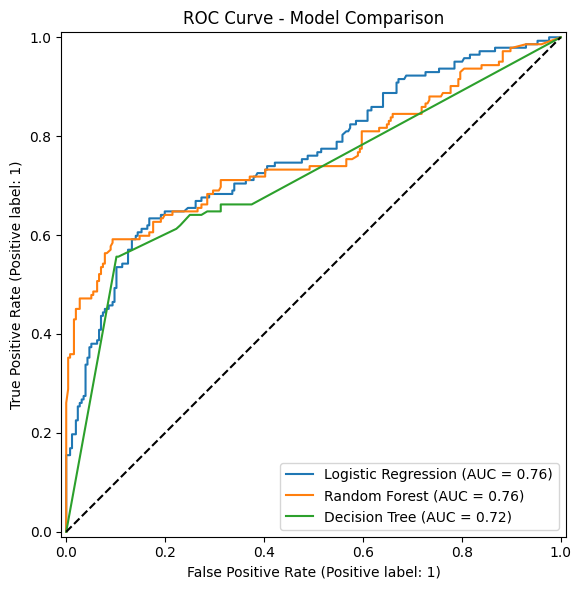

In [49]:
plt.figure(figsize=(9, 6))
ax = plt.gca()

for name, pipeline in trained_models.items():
    RocCurveDisplay.from_estimator(
        pipeline,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], "k--")
ax.set_title("ROC Curve - Model Comparison")

plt.tight_layout()
plt.show()

## **Feature Importance**

,Feature,Importance
1,num__AnnualIncome,0.264653
4,num__IncomePerFamilyMember,0.204875
0,num__Age,0.155671
2,num__FamilyMembers,0.114561
12,cat__EverTravelledAbroad_Yes,0.064188
11,cat__EverTravelledAbroad_No,0.054652
3,num__ChronicDiseases,0.044837
10,cat__FrequentFlyer_Yes,0.020438
9,cat__FrequentFlyer_No,0.017278
6,cat__Employment Type_Private Sector/Self Employed,0.012623


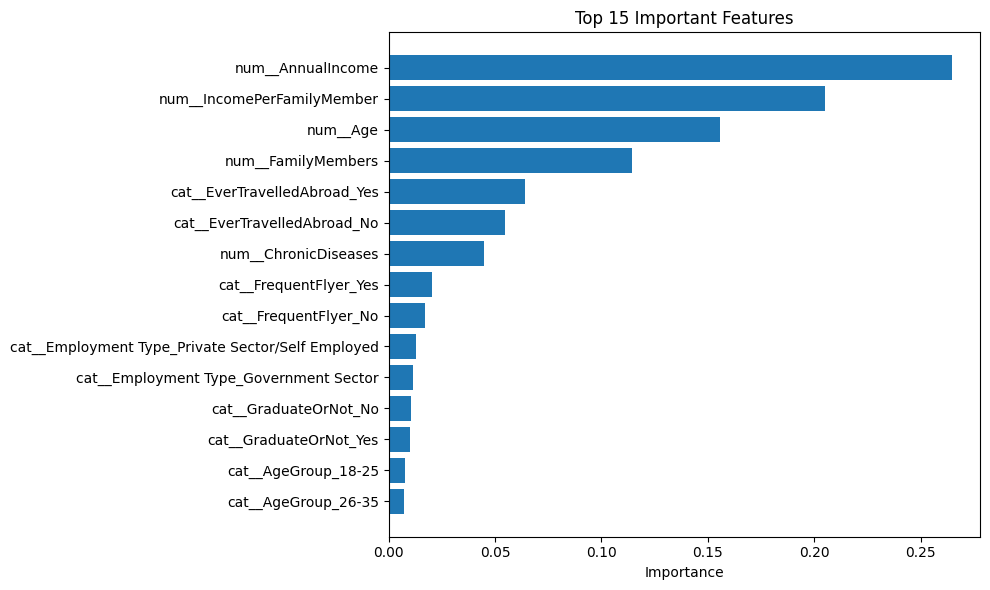

In [50]:
fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_model = best_model.named_steps["model"]

feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

if hasattr(fitted_model, "feature_importances_"):
    importance = fitted_model.feature_importances_

elif hasattr(fitted_model, "coef_"):
    importance = np.abs(fitted_model.coef_[0])

else:
    importance = None

if importance is not None:

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance
    }).sort_values(
        by="Importance",
        ascending=False
    ).head(15)

    display(importance_df)

    importance_df = importance_df.sort_values(
        by="Importance"
    )

    plt.figure(figsize=(10, 6))

    plt.barh(
        importance_df["Feature"],
        importance_df["Importance"]
    )

    plt.title("Top 15 Important Features")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

else:
    print("Feature importance unavailable.")

# **Sample Customer Prediction**

In [51]:
sample_customer = X_test.iloc[[0]].copy()

prediction = int(
    best_model.predict(sample_customer)[0]
)

probabilities = best_model.predict_proba(
    sample_customer
)[0]

print("Sample Customer Details:")
display(sample_customer)

print("\nPrediction:")

if prediction == 1:
    print("Customer may purchase travel insurance.")
else:
    print("Customer may not purchase travel insurance.")

print(
    f"Not Purchased Probability: {probabilities[0]:.2%}"
)

print(
    f"Purchased Probability: {probabilities[1]:.2%}"
)

Sample Customer Details:


,Age,Employment Type,GraduateOrNot,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,IncomePerFamilyMember,AgeGroup
1410,28,Private Sector/Self Employed,Yes,550000,8,0,No,No,68750.0,26-35



Prediction:
Customer may not purchase travel insurance.
Not Purchased Probability: 95.50%
Purchased Probability: 4.50%


# **Save the Trained Model**

In [52]:
import joblib

model_bundle = {
    "pipeline": best_model,
    "target_column": target_col,
    "feature_columns": X_model.columns.tolist()
}

joblib.dump(
    model_bundle,
    "travel_insurance_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


# **Save the Final Model**

In [53]:
results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Results saved successfully!")

display(results_df)

Results saved successfully!


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Random Forest,0.761307,0.694215,0.591549,0.638783,0.756836
1,Logistic Regression,0.726131,0.609272,0.647887,0.627986,0.760783
2,Decision Tree,0.716080,0.598639,0.619718,0.608997,0.717072
